# IBS + lower band mean reversion — single asset

Quantitativo's "2.11 Sharpe" strategy ([spec](../../docs/research/articles/quantitativo/mean_reversion_strategy_211_sharpe.md),
[robustness follow-up](../../docs/research/articles/quantitativo/robustness_211_sharpe_mean_reversion.md)),
on stored daily bars for SPY, QQQ, PSQ and QLD.

`adjusted OHLC → range mean, 10-day high, lower band, IBS, SMA300 → close-t signals → open-t+1 fills → returns, trades → source comparison`

**Rules (source):**

| item | rule |
| :-- | :-- |
| range mean | SMA25(High − Low) |
| lower band | 10-day rolling High − 2.5 × range mean |
| IBS | (Close − Low) / (High − Low) |
| entry | Close < lower band **and** IBS < 0.30 |
| exit | Close > yesterday's High |
| Improvement 1 | enter only when Close > SMA300 |
| Improvement 2 | also exit when Close < SMA300 |
| Improvement 3 | QQQ > SMA300: trade QQQ; QQQ < SMA300: trade PSQ with the same rules |

**Choices the source leaves open** (also in the [task doc](../../docs/tasks/2026-10-15/ibs_lower_band_single_asset_notebook.md)):
the 10-day high includes today's bar; IBS is undefined when High = Low; every signal is taken at
the close and filled at the next open; 1 bp per side; one position at a time with all equity, cash earns 0%.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p.resolve() for p in [Path.cwd(), *Path.cwd().parents] if (p / 'py' / 'apollo3').is_dir())
for variable, folder in [('XDG_CACHE_HOME', 'xdg-cache'), ('MPLCONFIGDIR', 'mplconfig')]:
    os.environ.setdefault(variable, str(ROOT / 'tmp' / folder))
    Path(os.environ[variable]).mkdir(parents=True, exist_ok=True)
if str(ROOT / 'py') not in sys.path:
    sys.path.insert(0, str(ROOT / 'py'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from apollo3.dailypx import read_daily_px
from apollo3.performance import ANNUALIZE, compute_summary_stats
from apollo3.store import FileStore

DATA_ROOT = Path(os.environ.get('A3_DATA_DIR', ROOT / 'workspace'))
SYMBOLS = ['SPY', 'QQQ', 'PSQ', 'QLD']

RANGE_WINDOW = 25     # source
HIGH_WINDOW = 10      # source
BAND_MULT = 2.5       # source
IBS_MAX = 0.30        # source
SMA_WINDOW = 300      # source (Improvements 1-3)
COST = 1 / 10_000     # robustness article: 1 bp per transaction, charged on each side

print('Python:', sys.executable)
print('Store:', DATA_ROOT)

Python: /Users/constantinpavlicu/dev/apollo3/venv/bin/python
Store: /Users/constantinpavlicu/dev/apollo3/workspace


## 1. Data

Split- and dividend-adjusted OHLC from the store. The overnight return across an ex-date uses
adjusted prices on both sides, so dividends are included.

In [2]:
st = FileStore(DATA_ROOT)
bars = {}
for symbol in SYMBOLS:
    frame = read_daily_px(st, 'US', symbol, adjusted=True)
    frame = frame.set_index(pd.DatetimeIndex(frame['date'], name='date'))
    assert frame.index.is_unique and frame.index.is_monotonic_increasing, symbol
    ohlc = frame[['open_adj', 'high_adj', 'low_adj', 'close_adj']].astype('float64')
    ohlc.columns = ['open', 'high', 'low', 'close']
    assert ohlc.notna().all().all() and (ohlc > 0).all().all(), symbol
    assert (ohlc.high >= ohlc[['open', 'close', 'low']].max(axis=1) - 1e-9).all(), symbol
    assert (ohlc.low <= ohlc[['open', 'close']].min(axis=1) + 1e-9).all(), symbol
    bars[symbol] = ohlc

display(pd.DataFrame({s: {'first': b.index[0].date(), 'last': b.index[-1].date(), 'rows': len(b),
                          'high == low days': int((b.high == b.low).sum())}
                      for s, b in bars.items()}).T)

,first,last,rows,high == low days
SPY,2008-01-02,2026-07-22,4667,0
QQQ,2008-01-02,2026-07-22,4667,0
PSQ,2008-01-02,2026-07-22,4667,0
QLD,2008-01-02,2026-01-30,4549,0


## 2. Indicators

Everything on row *t* uses bars up to and including *t*; it is known at the close of *t*.

In [3]:
def indicators(b):
    range_mean = (b.high - b.low).rolling(RANGE_WINDOW).mean()
    rolling_high = b.high.rolling(HIGH_WINDOW).max()
    span = b.high - b.low
    return pd.DataFrame({
        'close': b.close,
        'range_mean': range_mean,
        'rolling_high': rolling_high,
        'lower_band': rolling_high - BAND_MULT * range_mean,
        'ibs': (b.close - b.low) / span.where(span > 0),
        'sma': b.close.rolling(SMA_WINDOW).mean(),
        'prev_high': b.high.shift(1),
    })


ind = {s: indicators(b) for s, b in bars.items()}

# Spot check one QQQ date against a hand computation on the raw slice.
b, check_date = bars['QQQ'], bars['QQQ'].index[1000]
window = b.loc[:check_date]
hand_band = window.high.tail(HIGH_WINDOW).max() - BAND_MULT * (window.high - window.low).tail(RANGE_WINDOW).mean()
hand_ibs = (window.close.iloc[-1] - window.low.iloc[-1]) / (window.high.iloc[-1] - window.low.iloc[-1])
assert np.isclose(ind['QQQ'].loc[check_date, 'lower_band'], hand_band)
assert np.isclose(ind['QQQ'].loc[check_date, 'ibs'], hand_ibs)
print(f'{check_date.date()}: lower band {hand_band:.3f}, IBS {hand_ibs:.3f} match the hand computation')
display(ind['QQQ'].dropna().head().round(3))

2011-12-19: lower band 48.522, IBS 0.146 match the hand computation


,close,range_mean,rolling_high,lower_band,ibs,sma,prev_high
date,,,,,,,
2009-03-11,23.959,0.813,24.995,22.963,0.671,34.290,23.648
2009-03-12,24.753,0.821,24.831,22.778,0.932,34.228,24.166
2009-03-13,24.814,0.794,24.900,22.915,0.808,34.165,24.831
2009-03-16,24.399,0.789,25.021,23.048,0.089,34.108,24.900
2009-03-17,25.323,0.808,25.323,23.303,1.000,34.054,25.021


## 3. Simulator

One slot. At each close: if flat, the first instrument (in priority order) with an entry signal is
bought at the next open; if holding, an exit signal sells at the next open. `held[t]` is the
holding during day *t*'s session, decided at the close of *t − 1*.

Daily return on day *t* (from yesterday's close to today's close):

$$1 + r_t = \big(1 + h_{t-1}\,(O_t / C_{t-1} - 1)\big)\,\big(1 - c\,|h_t - h_{t-1}|\big)\,\big(1 + h_t\,(C_t / O_t - 1)\big)$$

The overnight leg belongs to the position carried from yesterday, the cost *c* is charged on equity at
the open when the position changes, and the intraday leg belongs to the position set at today's open.

In [4]:
def simulate(entries, exits):
    '''entries/exits: bool DataFrames (dates x instruments, columns in entry-priority order).
    Returns held: 0/1 DataFrame, held[t] = holding during day t's session.'''
    entry, exit_ = entries.to_numpy(), exits.to_numpy()
    held = np.zeros(entry.shape)
    current = -1                                   # instrument column held, -1 = flat
    for t in range(len(entries) - 1):
        if current < 0:
            signals = np.flatnonzero(entry[t])
            if len(signals):
                current = signals[0]
        elif exit_[t, current]:
            current = -1
        if current >= 0:
            held[t + 1, current] = 1.0
    return pd.DataFrame(held, index=entries.index, columns=entries.columns)


def daily_returns(held):
    total = pd.Series(0.0, index=held.index)
    for symbol in held.columns:
        b = bars[symbol].reindex(held.index)
        h, h_prev = held[symbol], held[symbol].shift(1, fill_value=0.0)
        overnight = (b.open / b.close.shift(1) - 1).fillna(0.0)
        intraday = b.close / b.open - 1
        total += (1 + h_prev * overnight) * (1 - COST * (h - h_prev).abs()) * (1 + h * intraday) - 1
    return total


def trade_list(held):
    rows = []
    for symbol in held.columns:
        h = held[symbol]
        change = h.diff().fillna(h)
        opens = bars[symbol].open.reindex(held.index)
        for entry_day, exit_day in zip(h.index[change > 0], h.index[change < 0]):
            rows.append({'symbol': symbol, 'entry': entry_day, 'exit': exit_day,
                         'days': held.index.get_loc(exit_day) - held.index.get_loc(entry_day),
                         'ret': opens[exit_day] / opens[entry_day] * (1 - COST) ** 2 - 1})
    return pd.DataFrame(rows).sort_values('entry', ignore_index=True)

## 4. Variants

All QQQ-based variants and SPY trade from the same first date (300 bars after 2008-01-02, the
SMA300 warm-up), so their compounding windows match. QLD has its own end date (2026-01-30).

In [5]:
def signals(i, index):
    i = i.reindex(index)
    entry = (i.close < i.lower_band) & (i.ibs < IBS_MAX)
    exit_ = i.close > i.prev_high
    above = i.close > i.sma
    return entry, exit_, above


def make_variants(ind, dates, qld_dates):
    '''(entries, exits) per variant; column order = entry priority.'''
    entry_qqq, exit_qqq, above_qqq = signals(ind['QQQ'], dates)
    entry_psq, exit_psq, _ = signals(ind['PSQ'], dates)
    entry_spy, exit_spy, _ = signals(ind['SPY'], dates)
    entry_qld, exit_qld, _ = signals(ind['QLD'], qld_dates)
    frame = lambda **cols: pd.DataFrame(cols)
    return {
        'SPY baseline':          (frame(SPY=entry_spy), frame(SPY=exit_spy)),
        'QQQ baseline':          (frame(QQQ=entry_qqq), frame(QQQ=exit_qqq)),
        'QQQ Improv 1 (regime)': (frame(QQQ=entry_qqq & above_qqq), frame(QQQ=exit_qqq)),
        'QQQ Improv 2 (stop)':   (frame(QQQ=entry_qqq), frame(QQQ=exit_qqq | ~above_qqq)),
        'QQQ/PSQ Improv 3':      (frame(QQQ=entry_qqq & above_qqq, PSQ=entry_psq & ~above_qqq),
                                  frame(QQQ=exit_qqq, PSQ=exit_psq)),
        'QLD baseline':          (frame(QLD=entry_qld), frame(QLD=exit_qld)),
    }


assert bars['PSQ'].index.equals(bars['QQQ'].index) and bars['SPY'].index.equals(bars['QQQ'].index)
start = bars['QQQ'].index[SMA_WINDOW]
dates = bars['QQQ'].loc[start:].index
qld_dates = bars['QLD'].loc[start:].index
VARIANTS = make_variants(ind, dates, qld_dates)
held = {name: simulate(*v) for name, v in VARIANTS.items()}
returns = {name: daily_returns(h) for name, h in held.items()}
trades = {name: trade_list(h) for name, h in held.items()}
print(f'Trading window: {dates[0].date()} to {dates[-1].date()} (QLD to {qld_dates[-1].date()})')

Trading window: 2009-03-12 to 2026-07-22 (QLD to 2026-01-30)


### Checks

1. **No look-ahead:** cut the raw bars at an earlier date, recompute indicators and signals, and rerun
   every variant. Holdings up to the cut must match the full run, since `held[t]` may only use bars up
   to *t − 1*.
2. **Return accounting:** compounding a trade's daily returns must equal open-to-open price return
   after costs on both sides.

In [6]:
cut = dates[len(dates) // 2]
ind_cut = {s: indicators(b.loc[:cut]) for s, b in bars.items()}
for name, (entries, exits) in make_variants(ind_cut, dates[dates <= cut], qld_dates[qld_dates <= cut]).items():
    assert simulate(entries, exits).equals(held[name].loc[:cut]), name

for name, t in trades.items():
    r = returns[name]
    for row in t.itertuples():
        days = r.index[(r.index >= row.entry) & (r.index <= row.exit)]
        assert np.isclose((1 + r.loc[days]).prod() - 1, row.ret, atol=1e-12), (name, row.entry)
print('no look-ahead and trade-return reconciliation checks pass for', len(VARIANTS), 'variants')

name = 'QQQ baseline'
display(trades[name].tail(8).round(4))

no look-ahead and trade-return reconciliation checks pass for 6 variants


,symbol,entry,exit,days,ret
202,QQQ,2025-11-14,2025-11-25,7,0.0064
203,QQQ,2025-12-18,2025-12-22,2,0.0200
204,QQQ,2026-01-21,2026-01-22,1,0.0209
205,QQQ,2026-02-04,2026-02-09,3,-0.0124
206,QQQ,2026-02-11,2026-02-19,5,-0.0222
207,QQQ,2026-03-23,2026-04-01,7,-0.0155
208,QQQ,2026-06-08,2026-06-12,4,-0.0005
209,QQQ,2026-06-24,2026-06-30,4,0.0121


## 5. Results vs the source

Source numbers are the article's (sample starts earlier than ours, costs not stated). Our numbers are
net of 1 bp per side. "Annual return" is CAGR; exposure is the share of sessions with a position.

"Sharpe" is over every session, flat days included, as everywhere else in apollo3.
"Sharpe in-market" uses only sessions with exposure. This is how the article computes Sharpe: rerunning
the baseline and Improvement 1 on the article's own window (1999-03-10 to 2024-05-17, QQQ from yfinance,
no costs) reproduces its CAGR, exposure and volatility, and only in-market Sharpe reproduces its Sharpe
(1.85 vs 1.83, 2.24 vs 2.25; all-days Sharpe is 0.92 and 0.86). The article's SPY run (1993–2024)
reproduces the same way (1.41 vs 1.39) once prices are split-adjusted but not dividend-adjusted, which is
what the article used (SPY buy & hold 8.3%, as reported). Our store prices include dividends. Use "Sharpe in-market" to compare with
the article and "Sharpe" for everything else. In-market Sharpe rises roughly as 1/√exposure, so it
rewards trading less and is not comparable with buy & hold or with other strategies.

In [7]:
SOURCE = pd.DataFrame({
    'SPY baseline':          [0.071, 1.39, np.nan, 0.180],
    'QQQ baseline':          [0.146, 1.83, -0.247, 0.200],
    'QQQ Improv 1 (regime)': [0.074, 2.25, -0.117, 0.117],
    'QQQ Improv 2 (stop)':   [0.130, 2.11, -0.203, np.nan],
    'QQQ/PSQ Improv 3':      [0.089, 2.02, -0.133, np.nan],
    'QLD baseline':          [0.117, 2.10, -0.290, np.nan],
}, index=['src CAGR', 'src Sharpe', 'src max DD', 'src exposure']).T


def summary(name):
    s = compute_summary_stats(returns[name])
    t = trades[name]
    wins, losses = t['ret'][t['ret'] > 0], t['ret'][t['ret'] <= 0]
    years = len(returns[name]) / ANNUALIZE
    gross = held[name].sum(axis=1)
    active = returns[name][(gross > 0) | (gross.shift(1) > 0)]     # sessions with any market exposure
    return {'CAGR': s['cagr'], 'Sharpe': s['sharpe'],
            'Sharpe in-market': active.mean() / active.std() * np.sqrt(ANNUALIZE),
            'max DD': s['max_drawdown'],
            'max DD days': s['max_dd_days'], 'exposure': held[name].sum(axis=1).mean(),
            'trades/yr': len(t) / years, 'win rate': (t['ret'] > 0).mean(),
            'avg trade': t['ret'].mean(), 'payoff': wins.mean() / -losses.mean(),
            'avg days held': t['days'].mean()}


buy_hold = {s: bars[s].close.loc[start:].pct_change().fillna(0.0) for s in ['QQQ', 'SPY']}
table = pd.DataFrame({name: summary(name) for name in VARIANTS}).T
for s, r in buy_hold.items():
    st_ = compute_summary_stats(r)
    table.loc[f'{s} buy & hold', ['CAGR', 'Sharpe', 'max DD', 'max DD days', 'exposure']] = [
        st_['cagr'], st_['sharpe'], st_['max_drawdown'], st_['max_dd_days'], 1.0]
table = table.join(SOURCE)
pct = ['CAGR', 'max DD', 'exposure', 'win rate', 'avg trade', 'src CAGR', 'src max DD', 'src exposure']
display(table.style.format({c: '{:.1%}' for c in pct} | {
    'Sharpe': '{:.2f}', 'Sharpe in-market': '{:.2f}', 'src Sharpe': '{:.2f}', 'payoff': '{:.2f}', 'trades/yr': '{:.1f}',
    'avg days held': '{:.1f}', 'max DD days': '{:.0f}'}, na_rep=''))

,CAGR,Sharpe,Sharpe in-market,max DD,max DD days,exposure,trades/yr,win rate,avg trade,payoff,avg days held,src CAGR,src Sharpe,src max DD,src exposure
SPY baseline,4.8%,0.52,1.14,-28.4%,1225,16.0%,11.4,74.7%,0.4%,0.62,3.5,7.1%,1.39,,18.0%
QQQ baseline,9.2%,0.80,1.70,-18.9%,574,17.7%,12.1,75.2%,0.7%,0.81,3.7,14.6%,1.83,-24.7%,20.0%
QQQ Improv 1 (regime),7.3%,0.80,1.90,-13.4%,515,14.2%,9.7,76.2%,0.8%,0.84,3.7,7.4%,2.25,-11.7%,11.7%
QQQ Improv 2 (stop),6.9%,0.67,1.48,-20.5%,639,15.2%,13.8,69.9%,0.5%,0.78,2.8,13.0%,2.11,-20.3%,
QQQ/PSQ Improv 3,7.0%,0.67,1.38,-22.8%,667,18.6%,12.2,72.2%,0.6%,0.75,3.8,8.9%,2.02,-13.3%,
QLD baseline,17.1%,0.78,1.62,-35.0%,642,18.5%,12.5,74.9%,1.4%,0.76,3.7,11.7%,2.10,-29.0%,
QQQ buy & hold,21.3%,1.04,,-35.1%,493,100.0%,,,,,,,,,
SPY buy & hold,16.2%,0.95,,-33.7%,488,100.0%,,,,,,,,,


### Sampling noise on Sharpe

These strategies trade a handful of times a year, so Sharpe is estimated from few independent bets.
The standard error below uses the usual $\sqrt{(1 + \mathrm{SR}^2/2)/T}$ in years. Paired
differences between variants share most trades, so they are tighter than the individual errors, but
small gaps are still noise.

In [8]:
se = pd.DataFrame({name: {'Sharpe': table.loc[name, 'Sharpe'],
                          'years': len(returns[name]) / ANNUALIZE,
                          'trades': len(trades[name])} for name in VARIANTS}).T
se['Sharpe s.e.'] = np.sqrt((1 + se.Sharpe ** 2 / 2) / se.years)
display(se.astype(float).round(2))

base = returns['QQQ baseline']
diff = pd.DataFrame({name: returns[name] - base for name in VARIANTS
                     if name.startswith('QQQ') and name != 'QQQ baseline'})
paired = pd.DataFrame({'ann. mean diff': diff.mean() * ANNUALIZE,
                       't-stat': diff.mean() / diff.std() * np.sqrt(len(diff))})
print('Daily return differences vs QQQ baseline:')
display(paired.round(3))

,Sharpe,years,trades,Sharpe s.e.
SPY baseline,0.52,17.33,198.0,0.26
QQQ baseline,0.80,17.33,210.0,0.28
QQQ Improv 1 (regime),0.80,17.33,168.0,0.28
QQQ Improv 2 (stop),0.67,17.33,239.0,0.27
QQQ/PSQ Improv 3,0.67,17.33,212.0,0.27
QLD baseline,0.78,16.86,211.0,0.28


Daily return differences vs QQQ baseline:


,ann. mean diff,t-stat
QQQ Improv 1 (regime),-0.019,-1.128
QQQ Improv 2 (stop),-0.022,-1.751
QQQ/PSQ Improv 3,-0.021,-0.951


## 6. Equity curves and drawdowns

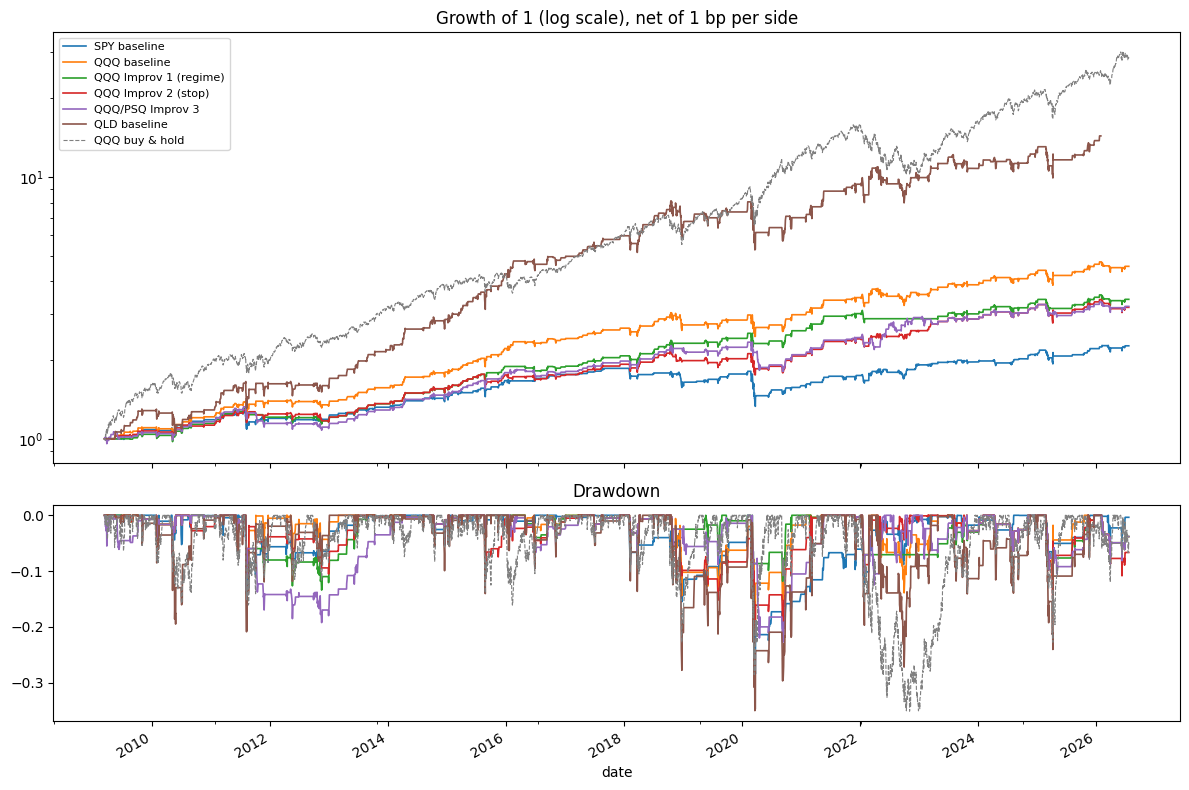

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[2, 1])
for name, r in {**returns, 'QQQ buy & hold': buy_hold['QQQ']}.items():
    wealth = (1 + r).cumprod()
    style = dict(color='grey', lw=0.8, ls='--') if 'buy & hold' in name else dict(lw=1.2)
    wealth.plot(ax=axes[0], label=name, logy=True, **style)
    (wealth / wealth.cummax() - 1).plot(ax=axes[1], **style)
axes[0].set_title('Growth of 1 (log scale), net of 1 bp per side')
axes[0].legend(fontsize=8)
axes[1].set_title('Drawdown')
plt.tight_layout(); plt.show()

## 7. One stretch of QQQ trades, close up

Close, lower band and SMA300, with baseline entries (filled at the next open) and exits.

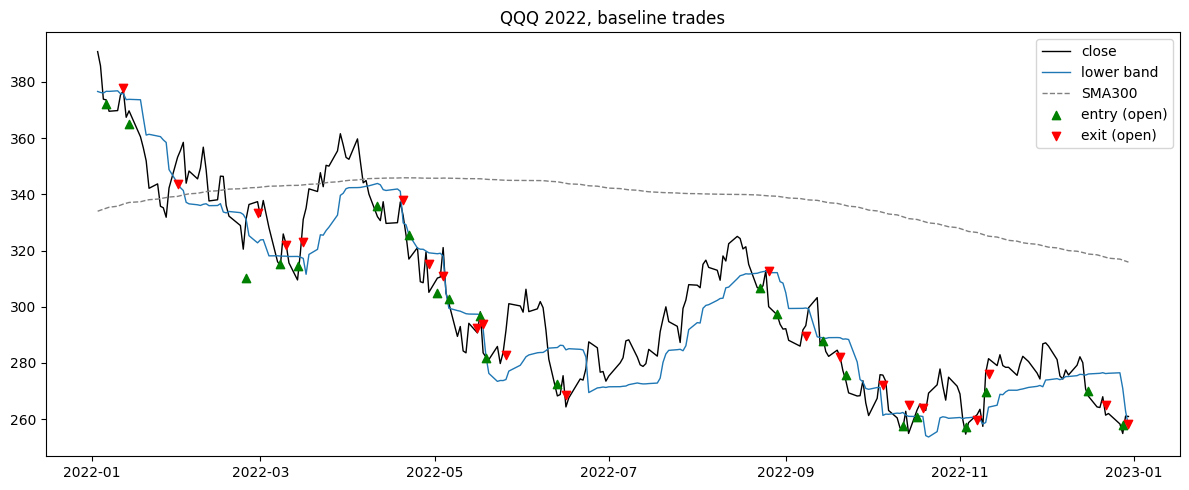

,symbol,entry,exit,days,ret
148,QQQ,2022-01-06,2022-01-12,4,0.0156
149,QQQ,2022-01-14,2022-01-31,10,-0.0585
150,QQQ,2022-02-24,2022-02-28,2,0.0740
151,QQQ,2022-03-08,2022-03-10,2,0.0207
152,QQQ,2022-03-14,2022-03-16,2,0.0278
153,QQQ,2022-04-11,2022-04-20,6,0.0064
154,QQQ,2022-04-22,2022-04-29,5,-0.0319
155,QQQ,2022-05-02,2022-05-04,2,0.0205
156,QQQ,2022-05-06,2022-05-16,6,-0.0349
157,QQQ,2022-05-17,2022-05-18,1,-0.0098


In [10]:
span = slice('2022-01-01', '2022-12-31')
i, b = ind['QQQ'].loc[span], bars['QQQ'].loc[span]
t = trades['QQQ baseline']
t = t[(t.entry >= b.index[0]) & (t.exit <= b.index[-1])]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(b.index, b.close, color='black', lw=1, label='close')
ax.plot(i.index, i.lower_band, color='tab:blue', lw=1, label='lower band')
ax.plot(i.index, i.sma, color='grey', lw=1, ls='--', label='SMA300')
ax.scatter(t.entry, b.open.loc[t.entry], marker='^', color='green', zorder=3, label='entry (open)')
ax.scatter(t.exit, b.open.loc[t.exit], marker='v', color='red', zorder=3, label='exit (open)')
ax.set_title('QQQ 2022, baseline trades'); ax.legend()
plt.tight_layout(); plt.show()
display(t.round(4))

## Reading the results

Numbers from the run on 2026-10-15 (data to 2026-07-22; trading from 2009-03-12).

- **Mechanics match the article:** QQQ baseline is in the market 17.7% of sessions (article: 20%),
  wins 75% of trades with payoff 0.81 (article: win rate > 60%, payoff < 1), and Improvement 1 cuts
  exposure and drawdown (14.2%, −13.4%; article 11.7%, −11.7%).
- **The article's Sharpe is over in-market sessions only** (confirmed by replication on its own
  window; see section 5). Like for like, our in-market Sharpe is 1.70 for the QQQ baseline (article
  1.83) and 1.90 for Improvement 1 (article 2.25); the remaining gap is the sample (ours 2009–2026,
  article 1999–2024). On the usual all-days basis the baseline is 0.80 here and 0.92 on the article's
  window.
- **The improvements do not help.** The article's Sharpe gains come mostly from lower exposure inflating
  in-market Sharpe; on its own window, all-days Sharpe is 0.92 (baseline) vs 0.86 (Improvement 1). Here,
  Improvement 1 keeps the Sharpe (0.80) with a smaller drawdown; Improvements 2 and 3 lower it (0.67). Against the QQQ baseline, each daily-return difference
  has |t| < 2, and the Sharpe standard error is about 0.28, so none of these gaps is resolved.
- **None of the variants beats QQQ buy & hold on Sharpe** (1.04) over 2009–2026, a strong bull market.
  The strategy's case is low exposure (~15–19% of sessions), which leaves capital free for other sleeves.